# Regular TCT vs Adaptive TCT — The Cost of (Not) Adapting

**Paper figures:** Figure 2 (`figures/adaptivity_waste_fixed_tau.png`) and Figure 3 (`figures/adaptivity_waste_diff_tau.png`).

Regular (non-adaptive) TCT requires fixing a target number of top rounds τ **upfront** and
prepaying the composition cost for all τ hits at registration:

    K_τ^std = (1 + α_τ) · τ / q,   α_τ = (β + √(β² + 2βτ)) / τ,   β = ln(1/δ)

This uses the *full* δ budget for one fixed target, giving a smaller K_τ than adaptive —
but it requires knowing τ in advance.

Adaptive TCT pays *incrementally*: K_1 at registration, then ΔK at each actual hit.
The total after k hits equals K_{k+1} — exactly what is needed. It splits δ across all
future k via the Zeta-2 allocation (δ_k = 6/(π²k²)·δ), which costs slightly more per hit
but never requires knowing the stopping time upfront.

| Panel | Scenario | τ vs actual tops | Effect |
|-------|----------|-----------------|--------|
| 1 | Right guess | τ ≈ actual | Both perform similarly |
| 2 | Too little  | τ < actual | Re-registration overhead → earlier dropout |
| 3 | Too much    | τ > actual | Over-prepayment → immediate dropout |

`TAU_MATCH`, `TAU_LOW`, and `TAU_HIGH` are configurable below.

In [1]:
import sys
sys.path.insert(0, '..')

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from simulation.accountants.adaptive_tct import AdaptiveTCTAccountant
from simulation.accountants.base import PrivacyAccountant
from simulation.calibration import q_from_epsilon, set_threshold_for_hit_rate
from simulation.datasets import generate_synthetic_population, PopulationConfig
from simulation.population import User
from simulation.query import compute_round_conversions, laplace_threshold_query
from simulation.notebook_utils import half_life, pad, PLOT_STYLE, TCT_Z_COLOR, IDP_COLOR

plt.rcParams.update(PLOT_STYLE)

ADAP_COLOR = TCT_Z_COLOR   # Adaptive TCT (Zeta-2)
REG_COLOR  = IDP_COLOR     # Regular TCT / Standard IDP

# ── Simulation parameters ────────────────────────────────────────────────────
EPSILON      = 0.01
DELTA        = 1e-2
EPS_BUDGET   = 0.8    # per-user ε budget
DELTA_BUDGET = 1.0
N_USERS      = 500
N_ROUNDS     = 500
TARGET_HIT   = 0.08   # 8% hit rate → ~40 global tops; mean rate 0.5 → ~20 per-user hits
SEED         = 42
POP_ALPHA    = 1.0    # Beta(1,1) = Uniform[0,1]
POP_BETA     = 1.0

# ── Configurable prepayment chunk sizes ──────────────────────────────────────
TAU_MATCH = 10   # within expected per-user range
TAU_LOW   = 3    # too small: re-registers every 3 hits
TAU_HIGH  = 25   # too large: registration cost exceeds budget → immediate dropout
# ─────────────────────────────────────────────────────────────────────────────

q = q_from_epsilon(EPSILON)
mean_rate = POP_ALPHA / (POP_ALPHA + POP_BETA)
total_tops = N_ROUNDS * TARGET_HIT
per_user_tops = total_tops * mean_rate

print(f'ε={EPSILON}, δ={DELTA:.0e}, q={q:.4f}')
print(f'EPS_BUDGET={EPS_BUDGET}')
print(f'Expected total top rounds: {total_tops:.0f}')
print(f'Mean conversion rate: {mean_rate:.2f}  →  expected per-user hits ≈ {per_user_tops:.1f}')
print()

# Pre-compute K_tau registration cost for each scenario
print('Standard TCT per-chunk costs (uses full δ, β = ln(1/δ)):')
beta_std = math.log(1.0 / DELTA)
for tau in [TAU_LOW, TAU_MATCH, TAU_HIGH]:
    at = (beta_std + math.sqrt(beta_std**2 + 2*beta_std*tau)) / tau
    Kt = (1.0 + at) / q * tau
    cost = Kt * EPSILON
    n_chunks = math.floor(EPS_BUDGET / cost) if cost <= EPS_BUDGET else 0
    max_tops = n_chunks * tau
    if cost > EPS_BUDGET:
        status = f'CANNOT REGISTER  (cost {cost:.4f} > budget {EPS_BUDGET})'
    else:
        status = f'{n_chunks} chunk(s) → max {max_tops} personal hits'
    print(f'  τ={tau:>3}:  K_τ={Kt:>6.1f},  chunk cost={cost:.4f}  →  {status}')

print()
print('Adaptive TCT cumulative cost after k personal hits:')
_acc = AdaptiveTCTAccountant(EPSILON, DELTA)
for k in [1, 5, 10, 11, 12, 15]:
    cost = _acc.budget_cost(_acc.compositions(k))
    marker = '  ← LAST before budget exhausted' if cost <= EPS_BUDGET and _acc.budget_cost(_acc.compositions(k+1)) > EPS_BUDGET else ''
    print(f'  k={k:>2}:  K_k·ε = {cost:.4f}{marker}')


ε=0.01, δ=1e-02, q=0.4975
EPS_BUDGET=0.8
Expected total top rounds: 40
Mean conversion rate: 0.50  →  expected per-user hits ≈ 20.0

Standard TCT per-chunk costs (uses full δ, β = ln(1/δ)):
  τ=  3:  K_τ=  29.3,  chunk cost=0.2933  →  2 chunk(s) → max 6 personal hits
  τ= 10:  K_τ=  50.8,  chunk cost=0.5075  →  1 chunk(s) → max 10 personal hits
  τ= 25:  K_τ=  91.4,  chunk cost=0.9138  →  CANNOT REGISTER  (cost 0.9138 > budget 0.8)

Adaptive TCT cumulative cost after k personal hits:
  k= 1:  K_k·ε = 0.2437
  k= 5:  K_k·ε = 0.5160
  k=10:  K_k·ε = 0.7375
  k=11:  K_k·ε = 0.7772  ← LAST before budget exhausted
  k=12:  K_k·ε = 0.8160
  k=15:  K_k·ε = 0.9279


## RegularTCTAccountant

Non-adaptive TCT with configurable prepayment chunk τ:
- **Registration** (first appearance): charge K_τ · ε + δ
- **Top hit within prepaid range** (cx ≤ τ·chunks): no charge
- **Top hit exceeding prepaid ceiling** (cx > τ·chunks): re-register, charge K_τ · ε again

Guessing τ correctly means paying the right amount once. Guessing too low means
paying again at every multiple-of-τ hit. Guessing too high means paying for phantom hits.

In [2]:
class RegularTCTAccountant(PrivacyAccountant):
    """
    Non-adaptive TCT: prepays K_tau * epsilon at registration for tau hits.
    Re-registers (another K_tau * epsilon, no delta) when hit count exceeds ceiling.

    Uses the full delta budget per Cohen & Lyu 2023 Theorem B.4:
        beta = ln(1/delta),  alpha_tau = (beta + sqrt(beta^2 + 2*beta*tau)) / tau
        K_tau = (1 + alpha_tau) * tau / q

    K_tau^regular < K_tau^adaptive because regular uses the full delta (smaller beta)
    while adaptive splits delta via the Zeta-2 allocation (larger beta_k per step).
    This makes regular cheaper per-chunk when tau is guessed correctly — but
    the benefit disappears when tau is wrong.

    Note on staircase timing: the cost curve jumps at k=tau because at that point
    you've exhausted your prepaid allotment and must immediately commit to the next
    chunk to continue participating. The accountant fires the charge one step later
    (at k=tau+1, when the ceiling is first exceeded), which is consistent with the
    "pay-as-you-go" interpretation of IDP filters.
    """

    def __init__(self, epsilon: float, delta: float, tau: int):
        if epsilon <= 0:
            raise ValueError(f'epsilon must be positive, got {epsilon}')
        if not 0 < delta < 1:
            raise ValueError(f'delta must be in (0,1), got {delta}')
        if tau < 1:
            raise ValueError(f'tau must be >= 1, got {tau}')

        self.epsilon = epsilon
        self.delta   = delta
        self.tau     = tau
        self.q       = 1.0 / (math.exp(epsilon) + 1.0)

        beta     = math.log(1.0 / delta)
        alpha_t  = (beta + math.sqrt(beta**2 + 2.0 * beta * tau)) / tau
        self.K_tau      = (1.0 + alpha_t) / self.q * tau
        self.chunk_cost = self.K_tau * epsilon

        self._cx     : dict[int, int] = {}  # hit count per user
        self._chunks : dict[int, int] = {}  # chunks prepaid per user

    def charge(
        self,
        user: User,
        is_top: bool,
        contributed: bool,
        round_num: int,
    ) -> tuple[float, float]:
        uid = user.user_id

        # First appearance: register, pay K_tau * epsilon + delta
        if uid not in self._cx:
            self._cx[uid]     = 0
            self._chunks[uid] = 1
            return (self.chunk_cost, self.delta)

        if is_top and contributed:
            self._cx[uid] += 1
            # Exceeded prepaid ceiling → re-register for next chunk
            if self._cx[uid] > self._chunks[uid] * self.tau:
                self._chunks[uid] += 1
                return (self.chunk_cost, 0.0)  # delta already paid at registration

        return (0.0, 0.0)

In [3]:
MAX_K = 30   # max target hits to display in figures

def regular_cost_at_k(tau, epsilon, delta, k):
    """
    Total budget committed after k actual top hits under regular TCT.

    Cost is a staircase: flat within each chunk of tau hits, then jumps by one
    chunk cost at k = tau, 2*tau, 3*tau, ... (n_chunks = floor(k/tau) + 1).
    """
    qq   = 1.0 / (math.exp(epsilon) + 1.0)
    beta = math.log(1.0 / delta)
    at   = (beta + math.sqrt(beta**2 + 2.0 * beta * tau)) / tau
    Kt   = (1.0 + at) / qq * tau
    chunk = Kt * epsilon
    n_chunks = math.floor(k / tau) + 1
    return n_chunks * chunk

def adaptive_cost_at_k(epsilon, delta, k):
    """Total budget committed after k actual top hits under adaptive TCT."""
    acc = AdaptiveTCTAccountant(epsilon, delta)
    return acc.budget_cost(acc.compositions(k + 1))


## Section 2: Simulation Setup

In [4]:
pop_cfg = PopulationConfig(
    n_users=N_USERS, alpha=POP_ALPHA, beta=POP_BETA,
    epsilon_budget=EPS_BUDGET,
    delta_budget=DELTA_BUDGET,
)

print('Calibrating threshold...')
calib_pop = generate_synthetic_population(pop_cfg, rng=np.random.default_rng(SEED))
T, hit_rate = set_threshold_for_hit_rate(
    calib_pop, EPSILON, TARGET_HIT,
    n_pilot=3000, rng=np.random.default_rng(SEED + 1)
)
print(f'T = {T:.2f},  empirical hit rate = {hit_rate:.4f}  (target {TARGET_HIT})')
actual_tops = hit_rate * N_ROUNDS
print(f'Expected top rounds in {N_ROUNDS} rounds ≈ {actual_tops:.1f}')
print(f'Expected per-user personal hits ≈ {actual_tops * mean_rate:.1f}  (mean rate={mean_rate:.2f})')

def run_sim(accountant_factory, seed=SEED):
    """Run one simulation; return (fraction_active_by_round, total_top_count, top_round_list)."""
    rng = np.random.default_rng(seed)
    pop = generate_synthetic_population(pop_cfg, rng=np.random.default_rng(seed))
    acc = accountant_factory()
    frac  = []
    tops  = 0
    top_rounds = []
    for r in range(N_ROUNDS):
        active = pop.active_users
        if not active:
            break
        parts = list(active)
        cnt, contribs = compute_round_conversions(parts, rng)
        is_top, _ = laplace_threshold_query(cnt, T, EPSILON, rng)
        if is_top:
            tops += 1
            top_rounds.append(r)
        for i, user in enumerate(parts):
            e, d = acc.charge(user=user, is_top=is_top,
                              contributed=contribs[i], round_num=r)
            user.epsilon_spent += e
            user.delta_spent   += d
        pop.drop_depleted()
        frac.append(pop.active_fraction)
    return frac, tops, top_rounds


Calibrating threshold...
T = 431.49,  empirical hit rate = 0.0800  (target 0.08)
Expected top rounds in 500 rounds ≈ 40.0
Expected per-user personal hits ≈ 20.0  (mean rate=0.50)


## Panel 1: Right Guess (τ = TAU_MATCH)

τ is set to approximately match the expected number of actual top rounds.
Regular and adaptive TCT should perform similarly — regular TCT is slightly cheaper
per-chunk (uses full δ), but the advantage is modest.

In [5]:
print(f'Panel 1: τ={TAU_MATCH} (right guess)')
frac_reg1, tops1, top_rounds1 = run_sim(lambda: RegularTCTAccountant(EPSILON, DELTA, TAU_MATCH))
frac_adp1, _,     _           = run_sim(lambda: AdaptiveTCTAccountant(EPSILON, DELTA))
hl_reg1 = half_life(frac_reg1); hl_adp1 = half_life(frac_adp1)
print(f'  Regular TCT  half-life = {hl_reg1} rounds')
print(f'  Adaptive TCT half-life = {hl_adp1} rounds')
print(f'  Total top rounds in sim: {tops1}')

Panel 1: τ=10 (right guess)
  Regular TCT  half-life = 500 rounds
  Adaptive TCT half-life = 500 rounds
  Total top rounds in sim: 19


## Panel 2: Too Little (τ = TAU_LOW)

τ is set well below the expected number of tops. Regular TCT must re-register
every τ hits, paying K_τ again each time. The cumulative re-registration cost
exhausts the budget faster than adaptive TCT's incremental payments.

In [6]:
print(f'Panel 2: τ={TAU_LOW} (too little)')
frac_reg2, tops2, _ = run_sim(lambda: RegularTCTAccountant(EPSILON, DELTA, TAU_LOW))
frac_adp2, _,     _ = run_sim(lambda: AdaptiveTCTAccountant(EPSILON, DELTA))
hl_reg2 = half_life(frac_reg2); hl_adp2 = half_life(frac_adp2)
print(f'  Regular TCT  half-life = {hl_reg2} rounds')
print(f'  Adaptive TCT half-life = {hl_adp2} rounds')

# Estimate re-registration events: users are dropped when ceiling exceeded
# Theoretical: max tops = floor(budget / chunk_cost) * tau
beta_std = math.log(1.0 / DELTA)
at_low   = (beta_std + math.sqrt(beta_std**2 + 2*beta_std*TAU_LOW)) / TAU_LOW
Kt_low   = (1.0 + at_low) / q * TAU_LOW
chunk_low = Kt_low * EPSILON
n_chunks  = math.floor(EPS_BUDGET / chunk_low)
max_tops  = n_chunks * TAU_LOW
print(f'  Theoretical max tops before dropout: {max_tops}  ({n_chunks} chunks × {TAU_LOW} tops)')

Panel 2: τ=3 (too little)
  Regular TCT  half-life = 270 rounds
  Adaptive TCT half-life = 500 rounds
  Theoretical max tops before dropout: 6  (2 chunks × 3 tops)


## Panel 3: Too Much (τ = TAU_HIGH)

τ is set far above the expected number of tops. The single registration
charge K_{τ_high} · ε exceeds the per-user budget — users are dropped
immediately at registration. Adaptive TCT charges only K_1 · ε at registration,
survives, and pays incrementally for each actual hit.

In [7]:
print(f'Panel 3: τ={TAU_HIGH} (too much)')
frac_reg3, tops3, _ = run_sim(lambda: RegularTCTAccountant(EPSILON, DELTA, TAU_HIGH))
frac_adp3, _,     _ = run_sim(lambda: AdaptiveTCTAccountant(EPSILON, DELTA))
hl_reg3 = half_life(frac_reg3); hl_adp3 = half_life(frac_adp3)

at_high  = (beta_std + math.sqrt(beta_std**2 + 2*beta_std*TAU_HIGH)) / TAU_HIGH
Kt_high  = (1.0 + at_high) / q * TAU_HIGH
chunk_high = Kt_high * EPSILON
print(f'  Regular TCT registration cost: {chunk_high:.4f}  (budget: {EPS_BUDGET})')
if chunk_high > EPS_BUDGET:
    print(f'  → Cost exceeds budget → ALL users dropped at registration')
print(f'  Regular TCT  half-life = {hl_reg3} rounds')
print(f'  Adaptive TCT half-life = {hl_adp3} rounds')

Panel 3: τ=25 (too much)
  Regular TCT registration cost: 0.9138  (budget: 0.8)
  → Cost exceeds budget → ALL users dropped at registration
  Regular TCT  half-life = 0 rounds
  Adaptive TCT half-life = 500 rounds


## Section 3: Budget Waste Decomposition

For a user who contributed to exactly k actual top rounds, how much budget
did each accountant charge, and how much was wasted on phantom hits?

In [8]:
# ── Waste decomposition: data setup ──────────────────────────────────────────
# representative per-user hit count based on actual simulation tops
rep_hits = max(1, round(tops1 * mean_rate))
print(f'Total top rounds: {tops1},  representative per-user hits ≈ {rep_hits}')
print(f'  (mean conversion rate {mean_rate:.2f} × {tops1} top rounds)')
print()

acc_adap  = AdaptiveTCTAccountant(EPSILON, DELTA)
adaptive_cost_rep = acc_adap.budget_cost(acc_adap.compositions(rep_hits + 1))

def regular_charged_at_k(tau, epsilon, delta, k):
    """
    Budget actually charged after k hits under the RegularTCTAccountant.

    Re-registration fires when the hit count exceeds the prepaid ceiling, so
    n_chunks = ceil(k / tau). This differs from regular_cost_at_k (which uses
    floor + 1) because the simulator charges on the crossing event, not upfront.
    """
    qq   = 1.0 / (math.exp(epsilon) + 1.0)
    beta = math.log(1.0 / delta)
    at   = (beta + math.sqrt(beta**2 + 2*beta*tau)) / tau
    Kt   = (1.0 + at) / qq * tau
    chunk = Kt * epsilon
    n_chunks = max(1, math.ceil(k / tau)) if k > 0 else 1
    return n_chunks * chunk


rows = []
for tau, label in [(TAU_LOW, f'τ={TAU_LOW} (too little)'),
                   (TAU_MATCH, f'τ={TAU_MATCH} (right)'),
                   (TAU_HIGH, f'τ={TAU_HIGH} (too much)')]:
    cost_k = regular_charged_at_k(tau, EPSILON, DELTA, rep_hits)
    waste  = cost_k - adaptive_cost_rep
    rows.append({
        'Scenario': label,
        'Total cost': cost_k,
        'Adaptive cost': adaptive_cost_rep,
        'Extra vs adaptive': waste,
        'Extra %': 100 * waste / adaptive_cost_rep,
    })

df = pd.DataFrame(rows)
print(f'Budget actually charged after {rep_hits} personal hits:')
print(f'  Adaptive TCT cost = {adaptive_cost_rep:.4f}')
print()
print(df.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

# tau sweep for Figure 2 (adaptivity_waste_fixed_tau.png)
tau_sweep   = list(range(1, 26))
costs_sweep = [regular_charged_at_k(tau, EPSILON, DELTA, rep_hits) for tau in tau_sweep]
opt_tau  = tau_sweep[costs_sweep.index(min(costs_sweep))]
opt_cost = min(costs_sweep)
print(f'\nOptimal τ for k={rep_hits} hits: τ={opt_tau}  cost={opt_cost:.4f}  '
      f'({"cheaper" if opt_cost < adaptive_cost_rep else "costlier"} than adaptive {adaptive_cost_rep:.4f})')

# k_vals for Figure 3 (adaptivity_waste_diff_tau.png)
k_vals = list(range(0, MAX_K + 1))

# Bar chart colors: green = cheaper than adaptive, orange = more expensive
COLOR_BETTER = '#2ca25f'
COLOR_WORSE  = '#fc8d59'


Total top rounds: 19,  representative per-user hits ≈ 10
  (mean conversion rate 0.50 × 19 top rounds)

Budget actually charged after 10 personal hits:
  Adaptive TCT cost = 0.7772

        Scenario  Total cost  Adaptive cost  Extra vs adaptive  Extra %
τ=3 (too little)      1.1734         0.7772             0.3961  50.9629
    τ=10 (right)      0.5075         0.7772            -0.2697 -34.7009
 τ=25 (too much)      0.9138         0.7772             0.1366  17.5719

Optimal τ for k=10 hits: τ=10  cost=0.5075  (cheaper than adaptive 0.7772)


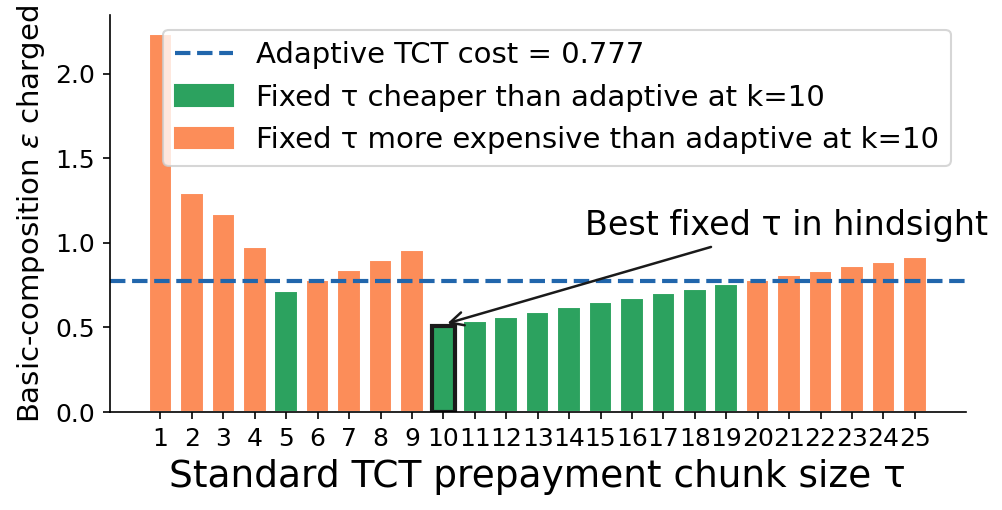

Saved figures/adaptivity_waste_fixed_tau.png


In [9]:
# ── Individual left panel: Cost vs τ bar chart ───────────────────────────────
fig, ax = plt.subplots(figsize=(7.0, 3.5))

bar_colors = [COLOR_BETTER if c <= adaptive_cost_rep else COLOR_WORSE for c in costs_sweep]
bars = ax.bar(tau_sweep, costs_sweep, color=bar_colors, edgecolor='white', width=0.75)
opt_idx = tau_sweep.index(opt_tau)
bars[opt_idx].set_edgecolor('#1a1a1a')
bars[opt_idx].set_linewidth(2.0)

ax.axhline(adaptive_cost_rep, color=ADAP_COLOR, lw=2, linestyle='--',
           label=f'Adaptive TCT = {adaptive_cost_rep:.3f}')

ann_xoffset = 4.5 if opt_tau <= 15 else -4.5
ann_ha      = 'left' if opt_tau <= 15 else 'right'
ax.annotate(
    f'Best fixed τ in hindsight',
    xy=(opt_tau, opt_cost + 0.01),
    xytext=(opt_tau + ann_xoffset, opt_cost + 0.50),
    fontsize=16, ha=ann_ha, va='bottom',
    arrowprops=dict(arrowstyle='->', color='#1a1a1a', lw=1.2),
)

ax.set_xlabel('Standard TCT prepayment chunk size τ', fontsize=18)
ax.set_ylabel(r'Basic-composition $\varepsilon$ charged', fontsize=14)
ax.set_xticks(tau_sweep)
ax.tick_params(axis='both', which='major', labelsize=12)

better_patch = mpatches.Patch(color=COLOR_BETTER, label=f'Fixed τ cheaper than adaptive at k={rep_hits}')
worse_patch  = mpatches.Patch(color=COLOR_WORSE,  label=f'Fixed τ more expensive than adaptive at k={rep_hits}')
ax.legend(handles=[ax.get_legend_handles_labels()[0][0], better_patch, worse_patch],
          labels=[f'Adaptive TCT cost = {adaptive_cost_rep:.3f}',
                  f'Fixed τ cheaper than adaptive at k={rep_hits}',
                  f'Fixed τ more expensive than adaptive at k={rep_hits}'],
          fontsize=14, loc='upper right')

plt.tight_layout()
fig.subplots_adjust(top=0.97)
plt.savefig('../figures/adaptivity_waste_fixed_tau.png', bbox_inches='tight', dpi=200)
plt.show()
print('Saved figures/adaptivity_waste_fixed_tau.png')


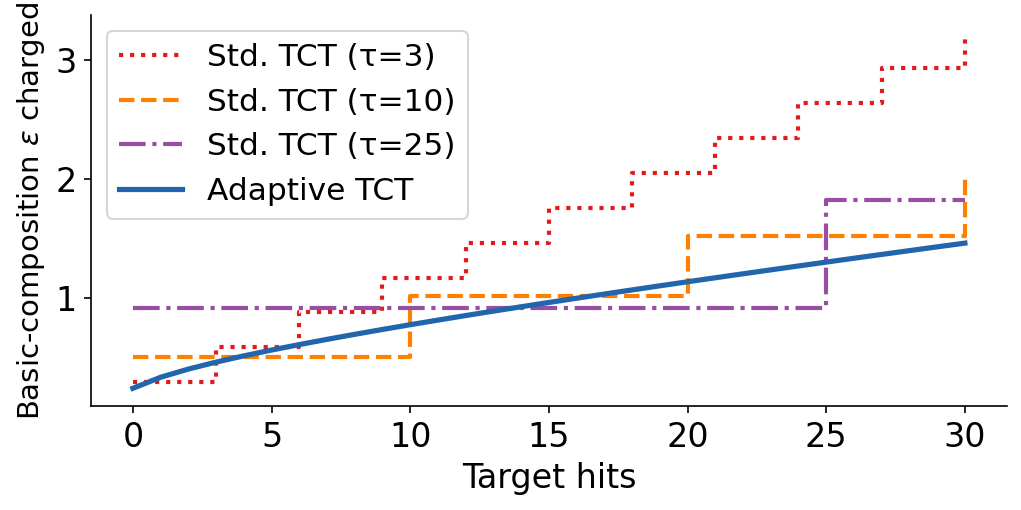

Saved figures/adaptivity_waste_diff_tau.png


In [10]:
# ── Individual right panel: Committed cost curves ────────────────────────────
fig, ax = plt.subplots(figsize=(7.0, 3.5))

curve_specs = [
    (TAU_LOW,   '#e31a1c', ':',  rf'Std. TCT (τ={TAU_LOW})'),
    (TAU_MATCH, '#ff7f00', '--', rf'Std. TCT (τ={TAU_MATCH})'),
    (TAU_HIGH,  '#984ea3', '-.', rf'Std. TCT (τ={TAU_HIGH})'),
]
for tau, col, ls, lbl in curve_specs:
    vals = [regular_cost_at_k(tau, EPSILON, DELTA, k) for k in k_vals]
    ax.step(k_vals, vals, where='post', color=col, lw=2, linestyle=ls, label=lbl)

adap_vals = [adaptive_cost_at_k(EPSILON, DELTA, k) for k in k_vals]
ax.plot(k_vals, adap_vals, color=ADAP_COLOR, lw=2.5, label='Adaptive TCT')

ax.set_xlabel('Target hits', fontsize=16)
ax.set_ylabel(r'Basic-composition $\varepsilon$ charged', fontsize=14)
ax.legend(fontsize=15, loc='upper left')
ax.tick_params(axis='both', which='major', labelsize=16)

plt.tight_layout()
fig.subplots_adjust(top=0.97)
plt.savefig('../figures/adaptivity_waste_diff_tau.png', bbox_inches='tight', dpi=200)
plt.show()
print('Saved figures/adaptivity_waste_diff_tau.png')
